In [ ]:
from google.colab import drive
from pathlib import Path
import pandas as pd
import numpy as np
import json
import matplotlib.pyplot as plt

In [ ]:
# Connect to Google Drive
drive.mount("/content/drive")

# Define the processed dataset location
PROCESSED_DIR = Path("/content/drive/MyDrive/Formative2 HMM/Processed Data")

Mounted at /content/drive


## 1. Window Segmentation

In [ ]:
# Load the recordings manifest
manifest_df = pd.read_csv(PROCESSED_DIR / "recordings_manifest.csv")

# Verify that all processed files are accessible
missing_files = [path for path in manifest_df["processed_csv"] if not (PROCESSED_DIR / path).is_file()]

print(f"Manifest entries: {len(manifest_df)}")
print(f"Missing processed files: {len(missing_files)}")
print("\nRecordings by activity and split:")
display(pd.crosstab(manifest_df["activity"], manifest_df["split"]))

assert len(manifest_df) == 58, "Unexpected number of recordings"
assert len(missing_files) == 0, "Some processed files are missing"

Manifest entries: 58
Missing processed files: 0

Recordings by activity and split:


split,Test,Train
activity,,
Jumping,2,12
Standing,2,12
Still,2,13
Walking,2,13


### 1.A. Window parameters choosing & justification

In [ ]:
# Window configuration
SAMPLING_HZ = 25
WINDOW_SECONDS = 2.0
OVERLAP_RATIO = 0.5

# Convert window settings into sample counts
WINDOW_SIZE = int(WINDOW_SECONDS * SAMPLING_HZ)
HOP_SIZE = int(WINDOW_SIZE * (1 - OVERLAP_RATIO))
FREQUENCY_RESOLUTION = SAMPLING_HZ / WINDOW_SIZE

print(f"Sampling frequency: {SAMPLING_HZ} Hz")
print(f"Window duration: {WINDOW_SECONDS} seconds")
print(f"Samples per window: {WINDOW_SIZE}")
print(f"Hop size: {HOP_SIZE} samples")
print(f"Overlap: {OVERLAP_RATIO * 100:.0f}%")
print(f"FFT frequency resolution: {FREQUENCY_RESOLUTION:.2f} Hz")

Sampling frequency: 25 Hz
Window duration: 2.0 seconds
Samples per window: 50
Hop size: 25 samples
Overlap: 50%
FFT frequency resolution: 0.50 Hz



### **Justification for Window Size and Overlap Selection**

For feature extraction, we selected **2-second windows with 50% overlap**, considering the standardized sampling frequency of **25 Hz**, the characteristics of the recorded activities, and the requirements of our Hidden Markov Model (HMM).

#### **1. Window Size (2 Seconds)**

At a sampling frequency of 25 Hz, the accelerometer and gyroscope each provide 25 measurements per second. Therefore, the number of samples in a 2-second window is calculated as:

$$
N = f_s \times T = 25 \times 2 = 50 \text{ samples}
$$

Where:
- $N$ = Number of samples per window
- $f_s$ = Sampling frequency (25 Hz)
- $T$ = Window duration (2 seconds)

Each window contains **50 synchronized observations across six sensor channels** (accelerometer and gyroscope measurements along the X, Y, and Z axes).

We selected 2 seconds because this interval is long enough to capture meaningful movement patterns, such as repeated steps during walking or takeoff and landing during jumping, while remaining short enough to preserve temporal information about activity changes.

Furthermore, a 2-second window provides an FFT frequency resolution of:

$$
\Delta f = \frac{f_s}{N} = \frac{25}{50} = 0.5 \text{ Hz}
$$

This frequency resolution allows us to extract meaningful frequency-domain features, including dominant frequency and spectral energy, which help distinguish rhythmic activities such as walking and jumping from relatively stationary activities such as standing and still.

#### **2. Window Overlap (50%)**

We selected a **50% overlap** to maintain continuity between consecutive windows and reduce the possibility of losing important movement information near window boundaries.

For a window containing 50 samples, the hop size is calculated as:

$$
H = N(1-r) = 50(1-0.5) = 25 \text{ samples}
$$

Where:
- $H$ = Hop size (number of samples between consecutive window starts)
- $N$ = Window size (50 samples)
- $r$ = Overlap ratio (0.5 or 50%)

The time interval between consecutive windows is therefore:

$$
T_{\text{hop}} = \frac{H}{f_s} = \frac{25}{25} = 1 \text{ second}
$$

Consequently, each new window begins **1 second after the previous window**, while sharing 25 samples with it.

This overlap produces more feature vectors from our relatively short recordings (5–10 seconds), providing additional temporal observations for the HMM without requiring new sensor recordings.

However, overlapping windows are correlated and do not represent independent observations. To prevent data leakage, segmentation is performed separately for each recording, preserving the existing training and testing assignments.

#### **3. Relevance to the Hidden Markov Model**

Each window is transformed into a feature vector containing time-domain and frequency-domain characteristics of the sensor signals. The resulting ordered feature vectors form an observation sequence for the HMM.

Using 2-second windows with 50% overlap balances three important considerations:

- **Temporal resolution:** A new feature vector is generated every second, allowing the model to track changes in movement patterns.
- **Feature reliability:** Each window contains 50 samples, providing sufficient observations for calculating statistical features and an initial estimate of frequency characteristics.
- **Computational efficiency:** The window length keeps the number of feature vectors manageable while preserving useful sequential information.

#### **4. Conclusion**

The selected **2-second window size with 50% overlap** provides a reasonable initial balance between temporal resolution, frequency resolution, and computational efficiency for our 25 Hz smartphone sensor data.

This configuration supports the extraction of meaningful features for distinguishing **Walking, Jumping, Standing, and Still** activities. However, alternative window sizes could be evaluated to determine whether they improve the HMM's classification performance.


### 1.B. Implementing the window segmentation function

In [ ]:
def segment_recording(df, window_size=WINDOW_SIZE, hop_size=HOP_SIZE):
    windows = []

    for start in range(0, len(df) - window_size + 1, hop_size):
        end = start + window_size
        window = df.iloc[start:end].copy()
        windows.append(window)

    return windows

This function returns a list of pandas DataFrames. Each DataFrame represents a 2-second sensor window.

We're deliberately using complete windows only. Any small remainder at the end of a recording will be left out instead of padding it with artificial readings.

### 1.C. Test segmentation on Walking_01

In [ ]:
# Load one processed recording
sample_path = PROCESSED_DIR / "Walking" / "Train" / "Walking_01.csv"
sample_df = pd.read_csv(sample_path)

# Segment the recording
sample_windows = segment_recording(sample_df)

print(f"Original recording shape: {sample_df.shape}")
print(f"Number of windows: {len(sample_windows)}")
print(f"First window shape: {sample_windows[0].shape}")
print(f"First window time range: {sample_windows[0]['time_s'].iloc[0]:.2f}–{sample_windows[0]['time_s'].iloc[-1]:.2f} seconds")
print(f"Last window time range: {sample_windows[-1]['time_s'].iloc[0]:.2f}–{sample_windows[-1]['time_s'].iloc[-1]:.2f} seconds")

display(sample_windows[0].head())

Original recording shape: (178, 7)
Number of windows: 6
First window shape: (50, 7)
First window time range: 0.00–1.96 seconds
Last window time range: 5.00–6.96 seconds


,time_s,acc_x,acc_y,acc_z,gyro_x,gyro_y,gyro_z
0,0.00,2.934740,-1.388709,-1.260505,-0.793904,-0.291714,2.399858
1,0.04,3.062367,-0.153252,-0.415845,-0.495836,-0.212456,1.909821
2,0.08,2.805541,0.691846,-0.860941,-0.261748,-0.076900,1.562714
3,0.12,2.868514,1.247124,-1.511452,-0.108912,-0.008752,1.206878
4,0.16,3.259012,1.633478,-1.855794,-0.071891,0.066796,0.910317


## 2. Time-Domain and Frequency-Domain Feature Extraction

Now we'll convert each window of sensor measurements into a numerical feature vector.

A window currently has `50 rows × 7 columns`. Instead of directly using all 50 measurements, we want to summarize its motion characteristics using relevant statistical and frequency-domain features.

### 2.A. Select our features

We will start with the following 12 features:

| Feature | Domain | Why it matters |
|---|---|---|
| Acceleration magnitude mean | Time | Average movement intensity |
| Acceleration magnitude standard deviation | Time | Variability of movement |
| Acceleration magnitude RMS | Time | Overall motion strength |
| Signal Magnitude Area (SMA) | Time | Combined movement across three axes |
| Gyroscope magnitude mean | Time | Average angular movement |
| Gyroscope magnitude standard deviation | Time | Variability in phone rotation |
| Gyroscope magnitude RMS | Time | Overall rotational intensity |
| Acceleration X–Y correlation | Time | Relationship between movements along different axes |
| Acceleration dominant frequency | Frequency | Repetitive movement patterns |
| Acceleration spectral energy | Frequency | Strength of periodic fluctuations |
| Gyroscope dominant frequency | Frequency | Dominant rotational rhythm |
| Gyroscope spectral energy | Frequency | Strength of rotational fluctuations |

### 2.B. Implement the frequency-domain feature function

In [ ]:
def extract_frequency_features(signal, sampling_hz=SAMPLING_HZ):
    signal = np.asarray(signal, dtype=float)
    centered_signal = signal - np.mean(signal)
    n = len(centered_signal)

    frequencies = np.fft.rfftfreq(n, d=1 / sampling_hz)
    fft_values = np.fft.rfft(centered_signal)
    power = np.abs(fft_values) ** 2 / n ** 2

    if n % 2 == 0:
        power[1:-1] *= 2
    else:
        power[1:] *= 2

    dominant_frequency = frequencies[1:][np.argmax(power[1:])]
    spectral_energy = np.sum(power[(frequencies >= 0.5) & (frequencies <= 8)])

    return dominant_frequency, spectral_energy

### **Explanation**

We subtract the signal's mean before applying the FFT because we're interested in the oscillating component of movement rather than its constant offset.

Dominant frequency identifies the nonzero frequency with the greatest power. For example, a repeated stepping pattern may produce peaks near its movement rhythm or harmonics.

Spectral energy measures how much signal power lies between 0.5 and 8 Hz. This is useful for distinguishing pronounced repetitive motion from minimal movement. This frequency band is an initial engineering choice, not a universal boundary for human activities.

For nearly motionless recordings, the dominant frequency may be determined mainly by tiny sensor fluctuations. Spectral energy helps us interpret how meaningful that frequency is.

### 2.C. Implement the complete feature extraction function

In [ ]:
def extract_window_features(window):
    acc = window[["acc_x", "acc_y", "acc_z"]].to_numpy(dtype=float)
    gyro = window[["gyro_x", "gyro_y", "gyro_z"]].to_numpy(dtype=float)

    acc_magnitude = np.linalg.norm(acc, axis=1)
    gyro_magnitude = np.linalg.norm(gyro, axis=1)

    acc_dominant_freq, acc_spectral_energy = extract_frequency_features(acc_magnitude)
    gyro_dominant_freq, gyro_spectral_energy = extract_frequency_features(gyro_magnitude)

    acc_x_std = np.std(acc[:, 0])
    acc_y_std = np.std(acc[:, 1])
    acc_xy_corr = np.corrcoef(acc[:, 0], acc[:, 1])[0, 1] if acc_x_std > 1e-8 and acc_y_std > 1e-8 else 0.0

    features = {
        "acc_mean": np.mean(acc_magnitude),
        "acc_std": np.std(acc_magnitude),
        "acc_rms": np.sqrt(np.mean(acc_magnitude ** 2)),
        "acc_sma": np.mean(np.sum(np.abs(acc), axis=1)),
        "gyro_mean": np.mean(gyro_magnitude),
        "gyro_std": np.std(gyro_magnitude),
        "gyro_rms": np.sqrt(np.mean(gyro_magnitude ** 2)),
        "acc_xy_corr": acc_xy_corr,
        "acc_dominant_freq": acc_dominant_freq,
        "acc_spectral_energy": acc_spectral_energy,
        "gyro_dominant_freq": gyro_dominant_freq,
        "gyro_spectral_energy": gyro_spectral_energy
    }

    return features

### 2.D. Test feature extraction on our first walking window

In [ ]:
# Extract features from the first walking window
first_window_features = extract_window_features(sample_windows[0])

# Display the extracted features
features_df = pd.DataFrame([first_window_features])

print(f"Number of extracted features: {len(first_window_features)}")
display(features_df.T.rename(columns={0: "Value"}).round(4))

Number of extracted features: 12


,Value
acc_mean,4.2125
acc_std,1.6278
acc_rms,4.5160
acc_sma,6.4631
gyro_mean,1.2316
gyro_std,0.6821
gyro_rms,1.4078
acc_xy_corr,0.7507
acc_dominant_freq,1.5000
acc_spectral_energy,2.6336


### 2.E. Extract features from all six walking windows

In [ ]:
# Extract one feature vector per window
walking_features = [extract_window_features(window) for window in sample_windows]

# Convert the extracted features into a DataFrame
walking_features_df = pd.DataFrame(walking_features)

print(f"Feature matrix shape: {walking_features_df.shape}")
print(f"Missing feature values: {walking_features_df.isna().sum().sum()}")
print(f"Infinite feature values: {np.isinf(walking_features_df.to_numpy()).sum()}")

display(walking_features_df.round(4))

Feature matrix shape: (6, 12)
Missing feature values: 0
Infinite feature values: 0


,acc_mean,acc_std,acc_rms,acc_sma,gyro_mean,gyro_std,gyro_rms,acc_xy_corr,acc_dominant_freq,acc_spectral_energy,gyro_dominant_freq,gyro_spectral_energy
0,4.2125,1.6278,4.5160,6.4631,1.2316,0.6821,1.4078,0.7507,1.5,2.6336,1.5,0.4633
1,3.7658,1.6774,4.1225,5.7048,1.3305,0.6183,1.4671,0.7277,1.5,2.7910,1.5,0.3801
2,4.4127,1.8872,4.7994,6.4788,1.4523,0.6259,1.5814,0.8315,1.5,3.5565,1.5,0.3905
3,4.0914,1.8001,4.4699,5.9723,1.3998,0.6534,1.5448,0.8648,1.5,3.2239,1.5,0.4259
4,3.7537,1.7996,4.1628,5.6095,1.2008,0.6127,1.3481,0.8766,1.5,3.2253,1.5,0.3723
5,3.9922,1.6037,4.3023,5.9402,1.3491,0.7404,1.5389,0.8405,1.5,2.5134,1.0,0.5467


### Extract Features from All 58 Recordings

In [ ]:
# Define output directory
FEATURES_DIR = PROCESSED_DIR.parent / "Features"
FEATURES_DIR.mkdir(parents=True, exist_ok=True)

# Extract features from every processed recording
feature_rows = []

for record in manifest_df.itertuples(index=False):
    recording_path = PROCESSED_DIR / record.processed_csv
    sensor_df = pd.read_csv(recording_path)
    windows = segment_recording(sensor_df)

    for window_index, window in enumerate(windows):
        features = extract_window_features(window)
        features.update({"recording_id": record.recording_id, "activity": record.activity, "split": record.split, "window_index": window_index, "window_start_s": window["time_s"].iloc[0], "window_end_s": window["time_s"].iloc[-1]})
        feature_rows.append(features)

# Build and organize the complete feature dataset
features_df = pd.DataFrame(feature_rows)
metadata_columns = ["recording_id", "activity", "split", "window_index", "window_start_s", "window_end_s"]
feature_columns = [column for column in features_df.columns if column not in metadata_columns]
features_df = features_df[metadata_columns + feature_columns]
features_df = features_df.sort_values(["activity", "split", "recording_id", "window_index"]).reset_index(drop=True)

# Validate all extracted features
feature_values = features_df[feature_columns].to_numpy(dtype=float)
recording_keys = features_df[["activity", "split", "recording_id"]].drop_duplicates()
expected_keys = manifest_df[["activity", "split", "recording_id"]].drop_duplicates()

assert len(feature_columns) == 12, "Incorrect number of extracted features"
assert np.isfinite(feature_values).all(), "Missing or infinite feature values detected"
assert len(recording_keys) == 58, "Not all recordings were processed"
assert set(map(tuple, recording_keys.to_numpy())) == set(map(tuple, expected_keys.to_numpy())), "Recording identity mismatch"
assert features_df.groupby(["activity", "split", "recording_id"])["window_index"].apply(lambda x: x.tolist() == list(range(len(x)))).all(), "Window order is incorrect"

# Separate training and testing datasets
train_features_df = features_df[features_df["split"] == "Train"].copy()
test_features_df = features_df[features_df["split"] == "Test"].copy()

# Save to Google Drive
train_features_df.to_csv(FEATURES_DIR / "train_features.csv", index=False)
test_features_df.to_csv(FEATURES_DIR / "test_features.csv", index=False)

# Display the results
print("FEATURE EXTRACTION SUMMARY")
print(f"Total recordings processed: {len(recording_keys)}")
print(f"Total feature windows: {len(features_df)}")
print(f"Training windows: {len(train_features_df)}")
print(f"Testing windows: {len(test_features_df)}")
print(f"Features per window: {len(feature_columns)}")
print(f"Missing values: {features_df[feature_columns].isna().sum().sum()}")
print(f"Infinite values: {np.isinf(feature_values).sum()}")
print("\nWINDOW DISTRIBUTION BY ACTIVITY")
display(pd.crosstab(features_df["activity"], features_df["split"]))
print("\nMEDIAN FEATURE VALUES BY ACTIVITY (TRAINING DATA)")
display(train_features_df.groupby("activity")[feature_columns].median().round(3))
print(f"\nFeature datasets saved to: {FEATURES_DIR}")

FEATURE EXTRACTION SUMMARY
Total recordings processed: 58
Total feature windows: 358
Training windows: 303
Testing windows: 55
Features per window: 12
Missing values: 0
Infinite values: 0

WINDOW DISTRIBUTION BY ACTIVITY


split,Test,Train
activity,,
Jumping,15,77
Standing,13,74
Still,14,77
Walking,13,75



MEDIAN FEATURE VALUES BY ACTIVITY (TRAINING DATA)


,acc_mean,acc_std,acc_rms,acc_sma,gyro_mean,gyro_std,gyro_rms,acc_xy_corr,acc_dominant_freq,acc_spectral_energy,gyro_dominant_freq,gyro_spectral_energy
activity,,,,,,,,,,,,
Jumping,8.823,3.971,9.484,12.453,1.414,0.645,1.525,0.677,4.0,15.578,2.0,0.381
Standing,0.268,0.082,0.288,0.396,0.069,0.041,0.079,0.370,1.0,0.006,0.5,0.002
Still,0.048,0.002,0.048,0.053,0.001,0.000,0.001,-0.055,2.0,0.000,1.5,0.000
Walking,3.446,1.193,3.848,5.060,1.049,0.521,1.182,0.595,1.0,1.396,1.5,0.260



Feature datasets saved to: /content/drive/MyDrive/Formative2 HMM/Features


## 3. Feature Correlation Analysis and Selection

TOP 10 FEATURE CORRELATIONS


Absolute correlation
gyro_mean gyro_rms                           0.9991
acc_mean  acc_rms                            0.9990
          acc_sma                            0.9989
acc_rms   acc_sma                            0.9972
gyro_std  gyro_rms                           0.9855
gyro_mean gyro_std                           0.9776
acc_std   acc_rms                            0.9763
acc_mean  acc_std                            0.9659
acc_std   acc_sma                            0.9607
          acc_spectral_energy                0.9518


FEATURE VARIABILITY
Constant features: 0
Highly correlated feature pairs (|r| >= 0.95): 10


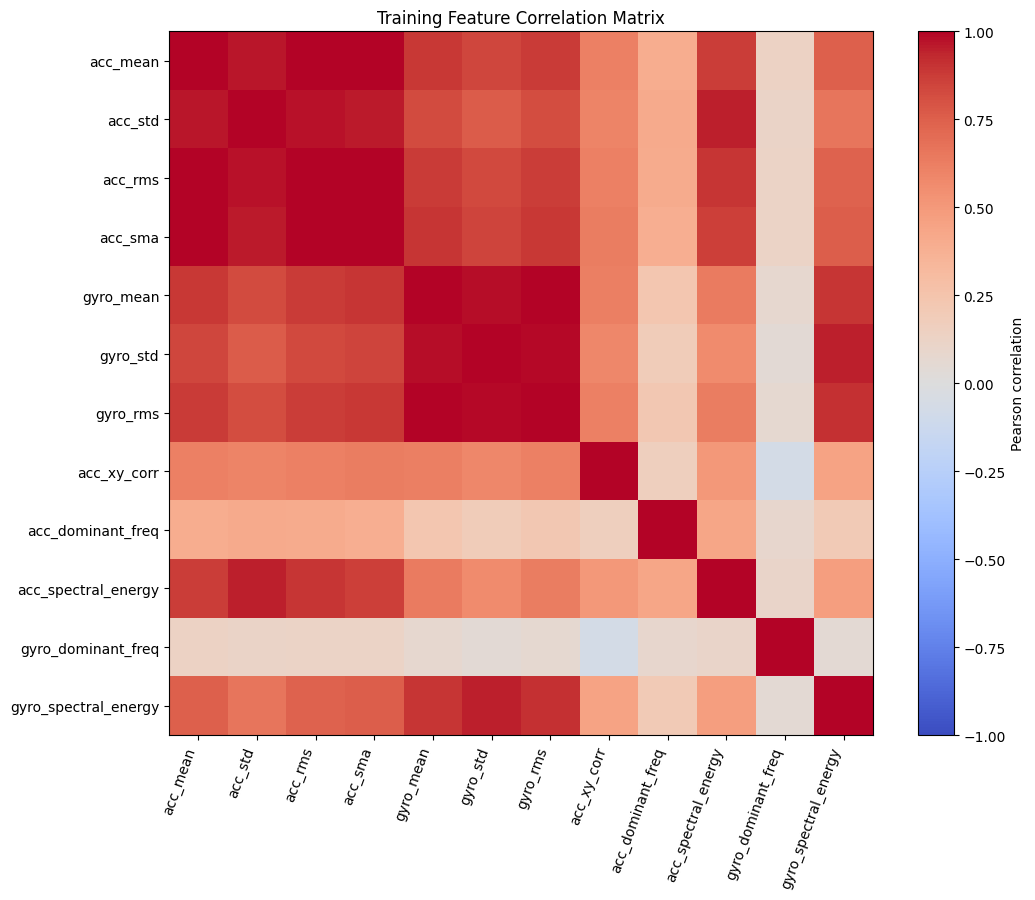


FEATURE SELECTION COMPLETED
Original features: 12
Selected features: 6
Feature configuration saved to: /content/drive/MyDrive/Formative2 HMM/Features/feature_selection.json
Correlation heatmap saved to: /content/drive/MyDrive/Formative2 HMM/Plots/Feature_Correlation_Heatmap.png


In [ ]:
# Analyze correlations using training data only
correlation_matrix = train_features_df[feature_columns].corr()
absolute_correlations = correlation_matrix.abs()
upper_triangle = absolute_correlations.where(np.triu(np.ones(absolute_correlations.shape), k=1).astype(bool))
strongest_pairs = upper_triangle.stack().sort_values(ascending=False)
feature_variability = train_features_df[feature_columns].std()

print("TOP 10 FEATURE CORRELATIONS")
display(strongest_pairs.head(10).rename("Absolute correlation").to_frame().round(4))

print("\nFEATURE VARIABILITY")
print(f"Constant features: {(feature_variability < 1e-8).sum()}")
print(f"Highly correlated feature pairs (|r| >= 0.95): {(strongest_pairs >= 0.95).sum()}")

# Save the correlation heatmap
fig, ax = plt.subplots(figsize=(11, 9))
heatmap = ax.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(feature_columns)), feature_columns, rotation=70, ha="right")
ax.set_yticks(range(len(feature_columns)), feature_columns)
ax.set_title("Training Feature Correlation Matrix")
fig.colorbar(heatmap, ax=ax, label="Pearson correlation")
fig.tight_layout()

PLOTS_DIR = PROCESSED_DIR.parent / "Plots"
PLOTS_DIR.mkdir(parents=True, exist_ok=True)
fig.savefig(PLOTS_DIR / "Feature_Correlation_Heatmap.png", dpi=300, bbox_inches="tight")
plt.show()

# Select a compact set of HMM observation features
SELECTED_FEATURES = ["acc_rms", "gyro_rms", "acc_xy_corr", "acc_dominant_freq", "acc_spectral_energy", "gyro_spectral_energy"]

assert all(feature in feature_columns for feature in SELECTED_FEATURES)

# Save feature selection configuration
selection_config = {"selected_features": SELECTED_FEATURES, "selection_basis": "Training data correlation analysis", "sampling_hz": SAMPLING_HZ, "window_size": WINDOW_SIZE, "hop_size": HOP_SIZE}

with open(FEATURES_DIR / "feature_selection.json", "w") as file:
    json.dump(selection_config, file, indent=4)

print("\nFEATURE SELECTION COMPLETED")
print(f"Original features: {len(feature_columns)}")
print(f"Selected features: {len(SELECTED_FEATURES)}")
print(f"Feature configuration saved to: {FEATURES_DIR / 'feature_selection.json'}")
print(f"Correlation heatmap saved to: {PLOTS_DIR / 'Feature_Correlation_Heatmap.png'}")